In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import (
    ttest_ind,
    f_oneway,
    chi2_contingency,
    shapiro,
    skew,
    kurtosis,
    t
)

df = pd.read_csv("customer_behavior.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Gender           4903 non-null   object 
 2   Region           4825 non-null   object 
 3   PurchaseAmount   4850 non-null   float64
 4   ProductCategory  4474 non-null   object 
 5   Churn            4735 non-null   objec

What are the average, median, and mode of PurchaseAmount?

In [5]:
mean_value = df["PurchaseAmount"].mean()
median_value = df["PurchaseAmount"].median()
mode_value = df["PurchaseAmount"].mode()
print("Mean:", mean_value)
print("Median:", median_value)
print("Mode:", mode_value.tolist())

Mean: 1003.9506701030928
Median: 998.0799999999999
Mode: [0.0]


outliers in the PurchaseAmount

In [6]:
Q1 = df["PurchaseAmount"].quantile(0.25)
Q3 = df["PurchaseAmount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[
    (df["PurchaseAmount"] < lower_bound) |
    (df["PurchaseAmount"] > upper_bound)
]
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))
print(outliers[["CustomerID", "PurchaseAmount"]])

Lower Bound: -306.51000000000033
Upper Bound: 2307.2300000000005
Number of Outliers: 15
      CustomerID  PurchaseAmount
195         1196         2318.33
265         1266         2496.41
348         1349         2688.69
411         1412         2349.16
826         1827         2578.89
1358        2359         2384.19
2285        3286         2457.05
2557        3558         2316.19
2681        3682         2400.69
3326        4327         2357.41
3438        4439         2688.88
3564        4565         2643.88
4345        5346         2472.62
4693        5694         2484.75
4808        5809         2642.06


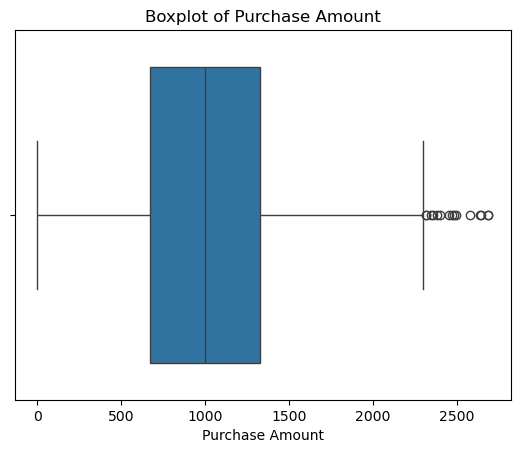

In [7]:
sns.boxplot(x=df["PurchaseAmount"])
plt.title("Boxplot of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.show()

skewness or kurtosis



Skewness: 0.10609189374631554
Excess Kurtosis: -0.2615105545319705


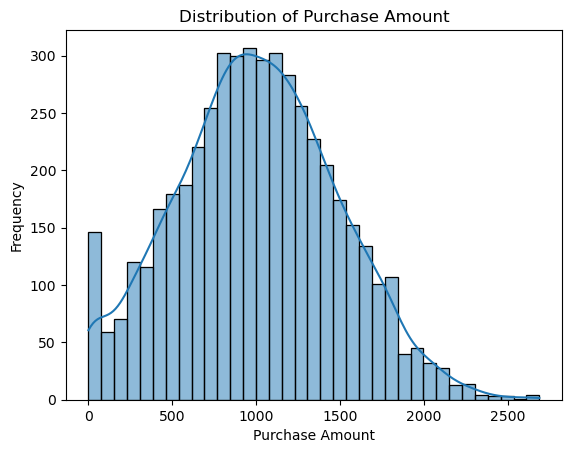

In [8]:
purchase = df["PurchaseAmount"].dropna()
skewness = purchase.skew()
kurtosis_value = purchase.kurtosis()
print("Skewness:", skewness)
print("Excess Kurtosis:", kurtosis_value)
sns.histplot(purchase, kde=True)
plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

difference in spending between male and female customers

In [9]:
male = df.loc[
    df["Gender"].astype(str).str.strip().str.lower() == "male",
    "PurchaseAmount"
].dropna()

female = df.loc[
    df["Gender"].astype(str).str.strip().str.lower() == "female",
    "PurchaseAmount"
].dropna()

print("Male Average:", male.mean())
print("Female Average:", female.mean())

# Welch's t-test does not assume equal population variances
t_stat, p_value = ttest_ind(
    male,
    female,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a statistically significant difference in spending.")
else:
    print("There is insufficient evidence of a difference in average spending.")

Male Average: 1019.1766093880973
Female Average: 987.8720464135021
T-statistic: 2.234798912073049
P-value: 0.025476849797238143
There is a statistically significant difference in spending.


relationship between ProductCategory and customer churn

In [10]:
contingency_table = pd.crosstab(
    df["ProductCategory"],
    df["Churn"]
)

print("Contingency Table:")
print(contingency_table)

chi2_stat, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("\nChi-square Statistic:", chi2_stat)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Product category and churn are significantly associated.")
else:
    print("Insufficient evidence of an association between product category and churn.")

Contingency Table:
Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604

Chi-square Statistic: 0.3960436652673918
Degrees of Freedom: 2
P-value: 0.8203519424988512
Insufficient evidence of an association between product category and churn.


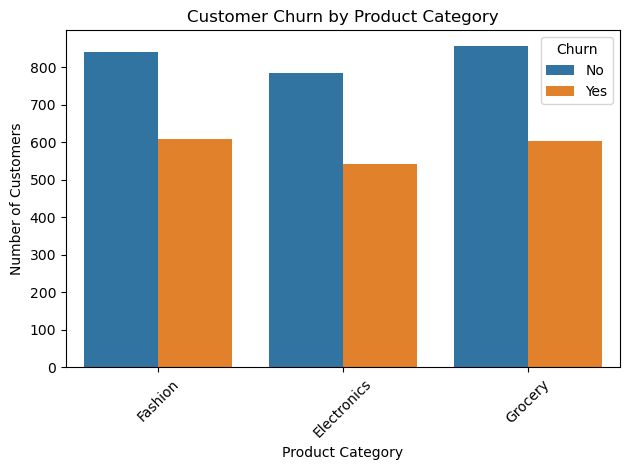

In [11]:
sns.countplot(
    data=df,
    x="ProductCategory",
    hue="Churn"
)

plt.title("Customer Churn by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Does PurchaseAmount vary significantly across different regions

In [12]:
region_data = [
    group["PurchaseAmount"].dropna().to_numpy()
    for _, group in df.groupby("Region")
]

region_means = df.groupby("Region")["PurchaseAmount"].mean()

print("Average Purchase Amount by Region:")
print(region_means)

if len(region_data) >= 2 and all(len(x) > 0 for x in region_data):
    f_stat, p_value = f_oneway(*region_data)

    print("\nF-statistic:", f_stat)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("At least one region has a significantly different mean.")
    else:
        print("Insufficient evidence of differences in regional mean.")
else:
    print("At least two non-empty regions are required.")

Average Purchase Amount by Region:
Region
East     1009.946017
North    1013.017952
South     997.603877
West      995.247327
Name: PurchaseAmount, dtype: float64

F-statistic: 0.38966786354806715
P-value: 0.760452802731563
Insufficient evidence of differences in regional mean.


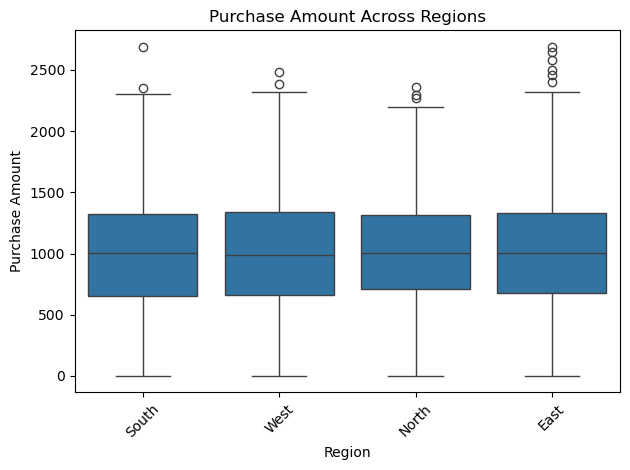

In [13]:
sns.boxplot(
    data=df,
    x="Region",
    y="PurchaseAmount"
)

plt.title("Purchase Amount Across Regions")
plt.xlabel("Region")
plt.ylabel("Purchase Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Which email campaign (A or B) performed better in terms of average PurchaseAmount

In [14]:
campaign_means = df.groupby(
    "CampaignGroup"
)["PurchaseAmount"].mean()

print("Average Purchase Amount by Campaign:")
print(campaign_means)

campaign_counts = df.groupby(
    "CampaignGroup"
)["PurchaseAmount"].count()

print("\nNumber of Observations:")
print(campaign_counts)

Average Purchase Amount by Campaign:
CampaignGroup
A    1011.945587
B     994.339965
Name: PurchaseAmount, dtype: float64

Number of Observations:
CampaignGroup
A    2350
B    2318
Name: PurchaseAmount, dtype: int64


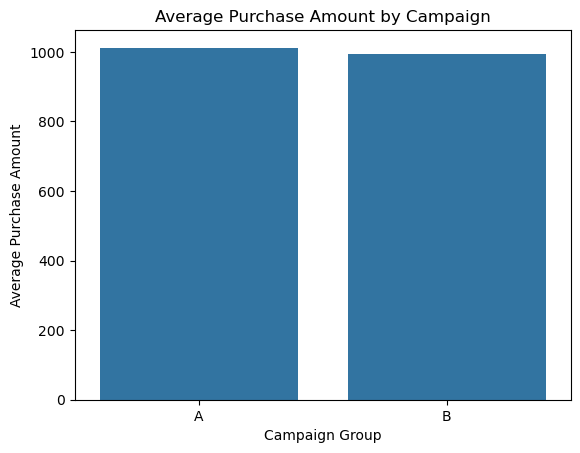

In [15]:
sns.barplot(
    data=df,
    x="CampaignGroup",
    y="PurchaseAmount",
    errorbar=None
)

plt.title("Average Purchase Amount by Campaign")
plt.xlabel("Campaign Group")
plt.ylabel("Average Purchase Amount")
plt.show()

In [16]:
campaign_a = df.loc[
    df["CampaignGroup"].astype(str).str.strip().str.upper() == "A",
    "PurchaseAmount"
].dropna()

campaign_b = df.loc[
    df["CampaignGroup"].astype(str).str.strip().str.upper() == "B",
    "PurchaseAmount"
].dropna()

print("Campaign A Mean:", campaign_a.mean())
print("Campaign B Mean:", campaign_b.mean())

t_stat, p_value = ttest_ind(
    campaign_a,
    campaign_b,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if campaign_a.mean() > campaign_b.mean():
    print("Campaign A has the higher average purchase amount.")
elif campaign_b.mean() > campaign_a.mean():
    print("Campaign B has the higher average purchase amount.")
else:
    print("Both campaigns have equal average purchase amounts.")

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("The difference is not statistically significant.")

Campaign A Mean: 1011.9455872340425
Campaign B Mean: 994.3399654874893
T-statistic: 1.2430861943551852
P-value: 0.21389858277292212
Campaign A has the higher average purchase amount.
The difference is not statistically significant.


Can we assume PurchaseAmount follows a normal distribution

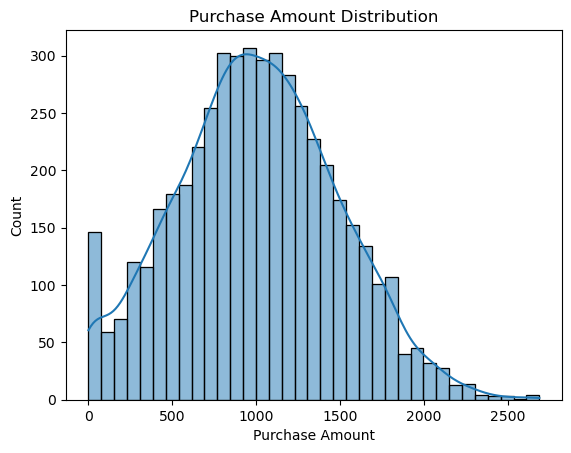

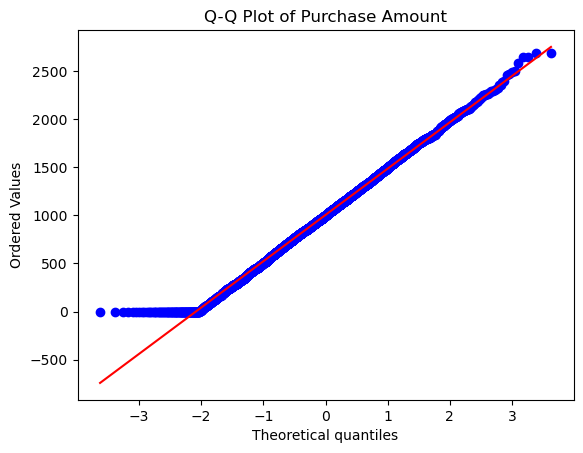

Shapiro-Wilk Statistic: 0.9949505740555428
P-value: 5.74412779948217e-12
The data provide evidence against normality.


In [17]:
purchase = df["PurchaseAmount"].dropna()


sns.histplot(purchase, kde=True)

plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount")
plt.show()


stats.probplot(
    purchase,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Purchase Amount")
plt.show()


sample = purchase.sample(
    n=min(len(purchase), 5000),
    random_state=42
)

if len(sample) >= 3:
    statistic, p_value = shapiro(sample)

    print("Shapiro-Wilk Statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("The data provide evidence against normality.")
    else:
        print("The test does not provide sufficient evidence against normality.")
else:
    print("At least three observations are required.")

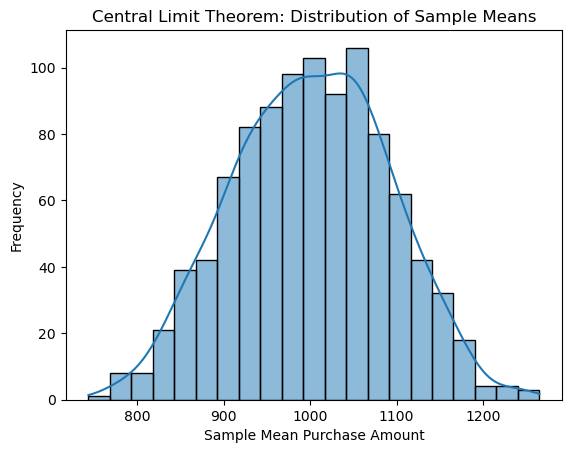

Original Data Mean: 1003.9506701030928
Mean of Sample Means: 1000.9630746666667
Standard Deviation of Sample Means: 89.931331064559


In [18]:
purchase = df["PurchaseAmount"].dropna()

sample_size = 30
number_of_samples = 1000

if len(purchase) >= sample_size:
    sample_means = []

    for i in range(number_of_samples):
        sample = purchase.sample(
            n=sample_size,
            replace=True,
            random_state=i
        )

        sample_means.append(sample.mean())


    sns.histplot(sample_means, kde=True)

    plt.title("Central Limit Theorem: Distribution of Sample Means")
    plt.xlabel("Sample Mean Purchase Amount")
    plt.ylabel("Frequency")
    plt.show()

    print("Original Data Mean:", purchase.mean())
    print("Mean of Sample Means:", np.mean(sample_means))
    print("Standard Deviation of Sample Means:", np.std(sample_means))
else:
    print("The dataset needs at least 30 valid observations for this example.")

In [19]:
purchase = df["PurchaseAmount"].dropna()

n = len(purchase)

if n >= 2:
    mean_value = purchase.mean()
    std_value = purchase.std(ddof=1)

    standard_error = std_value / np.sqrt(n)

    confidence_level = 0.95
    degrees_of_freedom = n - 1

    critical_value = t.ppf(
        (1 + confidence_level) / 2,
        degrees_of_freedom
    )

    margin_of_error = critical_value * standard_error

    lower_ci = mean_value - margin_of_error
    upper_ci = mean_value + margin_of_error

    print("Sample Size:", n)
    print("Mean Purchase Amount:", mean_value)
    print("Standard Error:", standard_error)
    print("95% Confidence Interval:")
    print("Lower Bound:", lower_ci)
    print("Upper Bound:", upper_ci)
else:
    print("At least two valid observations are required.")

Sample Size: 4850
Mean Purchase Amount: 1003.9506701030928
Standard Error: 6.922740985370979
95% Confidence Interval:
Lower Bound: 990.3789594609216
Upper Bound: 1017.522380745264
